In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

DATA_DIR = Path("../data/raw")
FIGURE_DIR = Path("../reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [2]:
transaction_df = pd.read_csv(
    DATA_DIR / "train_transaction.csv"
)

identity_df = pd.read_csv(
    DATA_DIR / "train_identity.csv"
)

print("Transaction dataset:", transaction_df.shape)
print("Identity dataset:", identity_df.shape)

Transaction dataset: (590540, 394)
Identity dataset: (144233, 41)


In [3]:
transaction_df.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
identity_df.head()

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


**Analyze fraud distribution**

In [5]:
print("Transaction columns:", transaction_df.shape[1])
print("Identity columns:", identity_df.shape[1])

print("\nFraud distribution:")
print(transaction_df["isFraud"].value_counts())

print("\nFraud percentage:")
print(
    transaction_df["isFraud"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Transaction columns: 394
Identity columns: 41

Fraud distribution:
isFraud
0    569877
1     20663
Name: count, dtype: int64

Fraud percentage:
isFraud
0    96.5
1     3.5
Name: proportion, dtype: float64


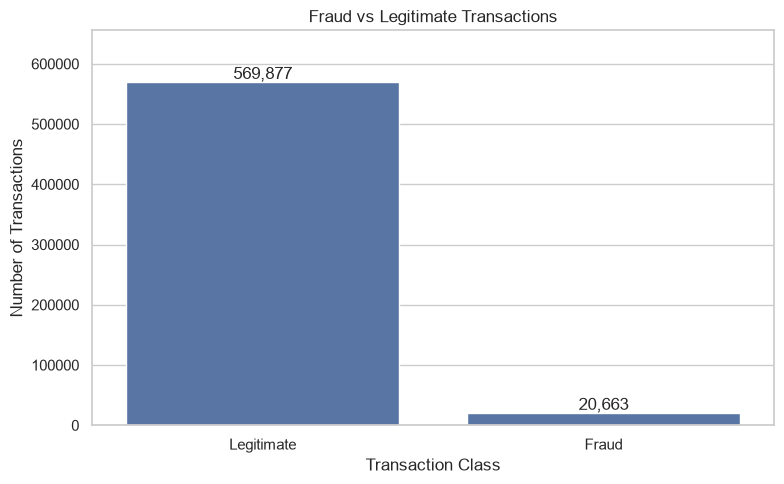

In [6]:
fraud_counts = (
    transaction_df["isFraud"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=["Legitimate", "Fraud"],
    y=fraud_counts.values
)

plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

for i, count in enumerate(fraud_counts.values):
    ax.text(
        i,
        count + 5000,
        f"{count:,}",
        ha="center"
    )

plt.ylim(0, fraud_counts.max() * 1.15)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "fraud_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Analyze transaction amounts**

In [7]:
amount_summary = (
    transaction_df.groupby("isFraud")["TransactionAmt"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

amount_summary.index = ["Legitimate", "Fraud"]

display(amount_summary)

,count,mean,median,std,min,max
Legitimate,569877,134.51,68.5,239.40,0.25,31937.39
Fraud,20663,149.24,75.0,232.21,0.29,5191.00


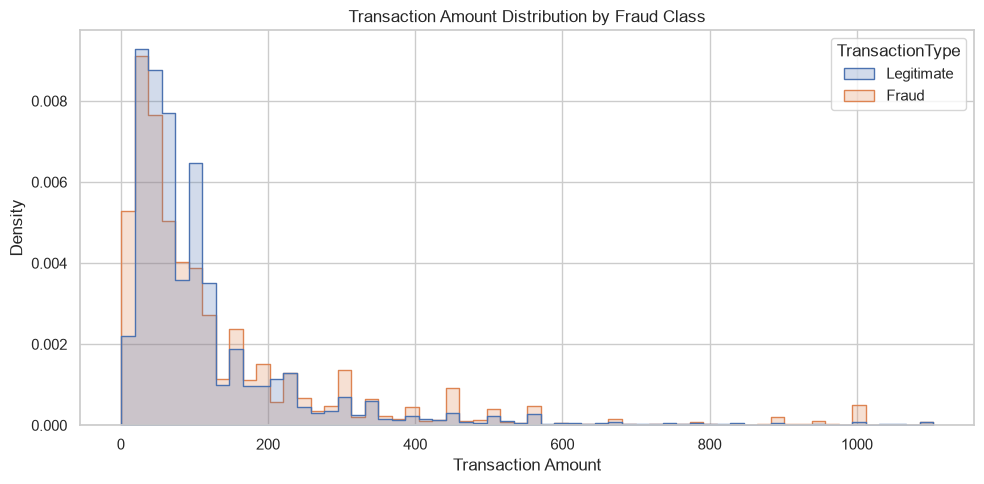

In [8]:
amount_limit = transaction_df["TransactionAmt"].quantile(0.99)

plot_df = transaction_df[
    transaction_df["TransactionAmt"] <= amount_limit
].copy()

plot_df["TransactionType"] = plot_df["isFraud"].map({
    0: "Legitimate",
    1: "Fraud"
})

plt.figure(figsize=(10, 5))

sns.histplot(
    data=plot_df,
    x="TransactionAmt",
    hue="TransactionType",
    bins=60,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Transaction Amount Distribution by Fraud Class")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")
plt.tight_layout()

plt.savefig(
    "../reports/figures/transaction_amount_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Analyze missing values**

In [9]:
missing_values = (
    transaction_df.isnull().mean() * 100
).sort_values(ascending=False)

missing_summary = pd.DataFrame({
    "Feature": missing_values.index,
    "Missing_Percentage": missing_values.values
})

display(missing_summary.head(20))

print(
    "Features with over 50% missing values:",
    (missing_values > 50).sum()
)

,Feature,Missing_Percentage
0,dist2,93.628374
1,D7,93.409930
2,D13,89.509263
3,D14,89.469469
4,D12,89.041047
5,D6,87.606767
6,D9,87.312290
7,D8,87.312290
8,V153,86.123717
9,V139,86.123717


Features with over 50% missing values: 174


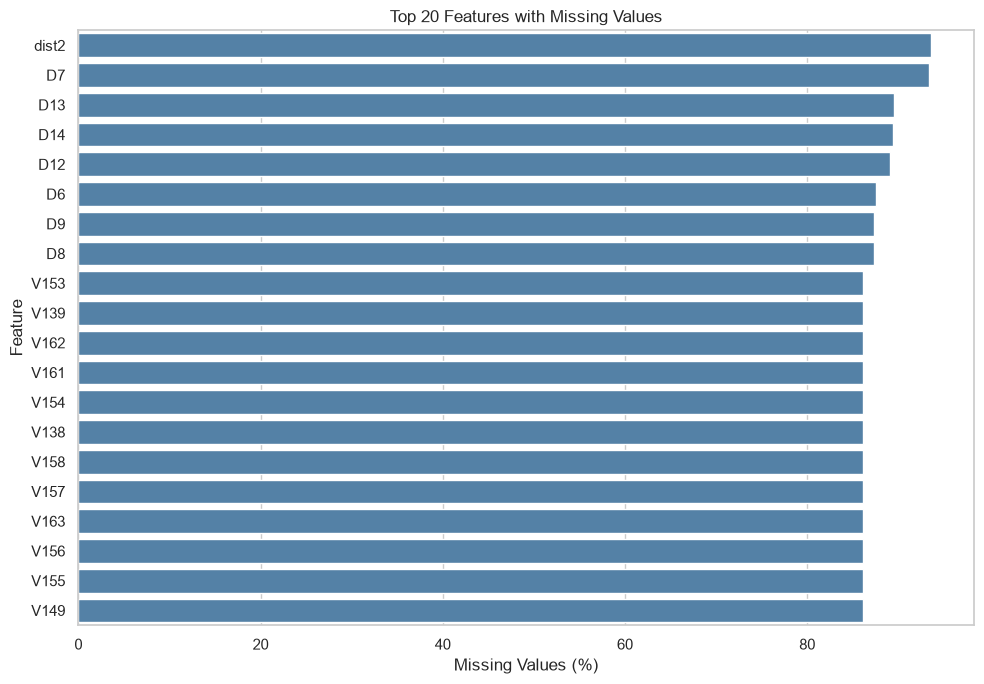

In [10]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=missing_summary.head(20),
    x="Missing_Percentage",
    y="Feature",
    color="steelblue"
)

plt.title("Top 20 Features with Missing Values")
plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    "../reports/figures/missing_values.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Analyze fraud patterns over time**

In [11]:
transaction_df["TransactionDay"] = (
    transaction_df["TransactionDT"] // 86400
).astype(int)

daily_fraud = (
    transaction_df.groupby("TransactionDay")
    .agg(
        Total_Transactions=("isFraud", "size"),
        Fraud_Transactions=("isFraud", "sum")
    )
    .reset_index()
)

daily_fraud["Fraud_Rate"] = (
    daily_fraud["Fraud_Transactions"]
    / daily_fraud["Total_Transactions"] * 100
)

display(daily_fraud.head(10))

/var/folders/_t/5l02f04n6w15dqdjv_b0b54r0000gn/T/ipykernel_3753/1889412000.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  transaction_df["TransactionDay"] = (


,TransactionDay,Total_Transactions,Fraud_Transactions,Fraud_Rate
0,1,5122,112,2.186646
1,2,3730,123,3.297587
2,3,3241,92,2.838630
3,4,4036,115,2.849356
4,5,3964,127,3.203835
5,6,3717,99,2.663438
6,7,3786,136,3.592182
7,8,3999,93,2.325581
8,9,3907,119,3.045815
9,10,3445,90,2.612482


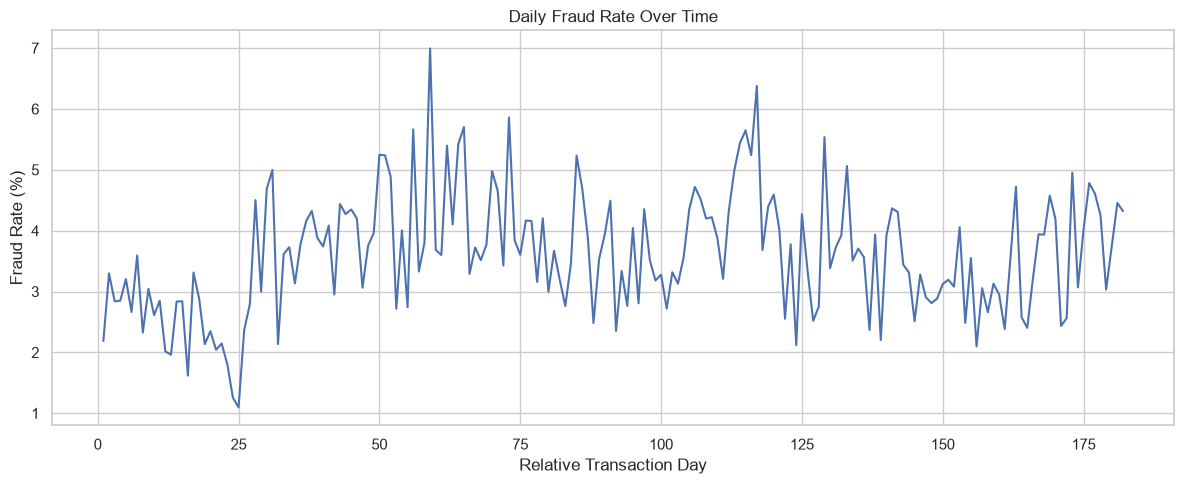

In [12]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=daily_fraud,
    x="TransactionDay",
    y="Fraud_Rate"
)

plt.title("Daily Fraud Rate Over Time")
plt.xlabel("Relative Transaction Day")
plt.ylabel("Fraud Rate (%)")

plt.tight_layout()

plt.savefig(
    "../reports/figures/daily_fraud_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
product_fraud = (
    transaction_df.groupby("ProductCD")
    .agg(
        Total_Transactions=("isFraud", "size"),
        Fraud_Transactions=("isFraud", "sum"),
        Fraud_Rate=("isFraud", "mean")
    )
    .reset_index()
)

product_fraud["Fraud_Rate"] *= 100

display(
    product_fraud.sort_values(
        "Fraud_Rate",
        ascending=False
    )
)

,ProductCD,Total_Transactions,Fraud_Transactions,Fraud_Rate
0,C,68519,8008,11.687269
3,S,11628,686,5.899553
1,H,33024,1574,4.766231
2,R,37699,1426,3.782594
4,W,439670,8969,2.039939


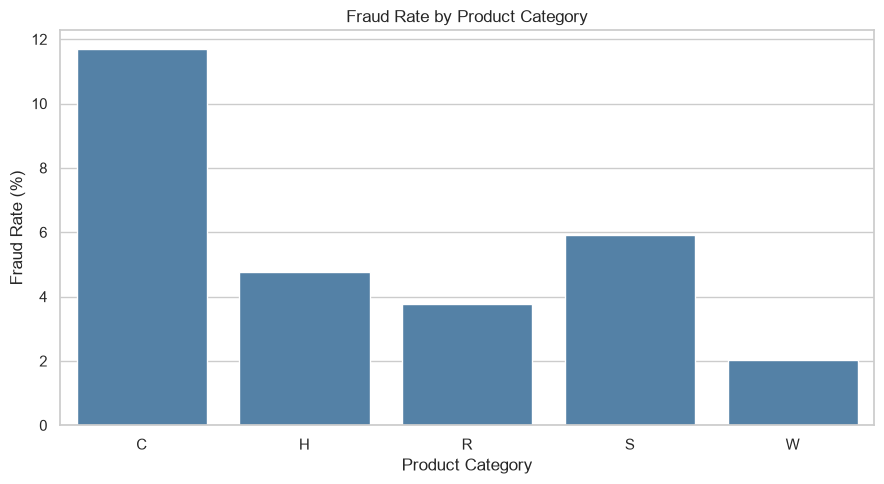

In [14]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=product_fraud,
    x="ProductCD",
    y="Fraud_Rate",
    color="steelblue"
)

plt.title("Fraud Rate by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Fraud Rate (%)")

plt.tight_layout()

plt.savefig(
    "../reports/figures/fraud_by_product.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Analyze the identity dataset**

In [15]:
print("Identity dataset shape:", identity_df.shape)

print("\nFirst five rows:")
display(identity_df.head())

print("\nIdentity column names:")
print(identity_df.columns.tolist())

Identity dataset shape: (144233, 41)

First five rows:


,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS



Identity column names:
['TransactionID', 'id_01', 'id_02', 'id_03', 'id_04', 'id_05', 'id_06', 'id_07', 'id_08', 'id_09', 'id_10', 'id_11', 'id_12', 'id_13', 'id_14', 'id_15', 'id_16', 'id_17', 'id_18', 'id_19', 'id_20', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25', 'id_26', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_32', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo']


In [16]:
merged_df = transaction_df.merge(
    identity_df,
    on="TransactionID",
    how="left",
    validate="one_to_one"
)

print("Merged dataset shape:", merged_df.shape)

print(
    "Transactions with identity information:",
    merged_df["TransactionID"].isin(
        identity_df["TransactionID"]
    ).sum()
)

Merged dataset shape: (590540, 435)
Transactions with identity information: 144233


In [17]:
merged_df["HasIdentity"] = (
    merged_df["TransactionID"]
    .isin(identity_df["TransactionID"])
)

identity_fraud = (
    merged_df.groupby("HasIdentity")
    .agg(
        Total_Transactions=("isFraud", "size"),
        Fraud_Transactions=("isFraud", "sum"),
        Fraud_Rate=("isFraud", "mean")
    )
    .reset_index()
)

identity_fraud["Fraud_Rate"] *= 100

display(identity_fraud)

/var/folders/_t/5l02f04n6w15dqdjv_b0b54r0000gn/T/ipykernel_3753/2353503029.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged_df["HasIdentity"] = (


,HasIdentity,Total_Transactions,Fraud_Transactions,Fraud_Rate
0,False,446307,9345,2.093850
1,True,144233,11318,7.847025


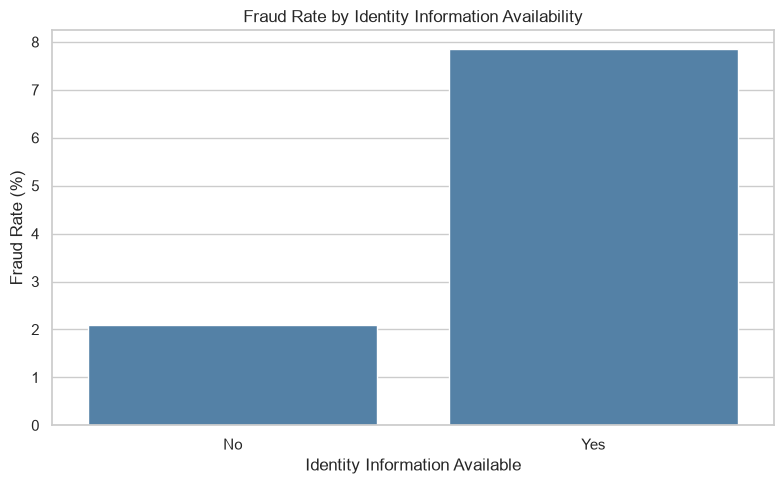

In [18]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=identity_fraud,
    x="HasIdentity",
    y="Fraud_Rate",
    color="steelblue"
)

plt.title("Fraud Rate by Identity Information Availability")
plt.xlabel("Identity Information Available")
plt.ylabel("Fraud Rate (%)")
plt.xticks([0, 1], ["No", "Yes"])

plt.tight_layout()

plt.savefig(
    "../reports/figures/fraud_by_identity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## Exploratory Data Analysis — Key Findings

### 1. Dataset Overview
- Analyzed 590,540 transactions with 394 original transaction columns.
- Identified 20,663 fraudulent transactions (3.50%).
- Joined transaction data with 144,233 identity records.

### 2. Class Imbalance
- Legitimate transactions represent 96.50% of the dataset.
- Fraudulent transactions represent only 3.50%.
- Precision, recall, F1-score, and PR-AUC will be important evaluation metrics.

### 3. Missing Values
- 174 of the original 394 transaction columns contain more than 50% missing values.
- Missing-value indicators and imputation strategies should be investigated before removing sparse features.

### 4. Product Category Analysis
- Product category C has the highest observed fraud rate (~11.7%).
- Product category W has the lowest observed fraud rate (~2.0%).
- ProductCD may be useful for fraud prediction.

### 5. Identity Information
- Transactions with identity information show an observed fraud rate of approximately 7.8%.
- Transactions without identity information show approximately 2.1%.
- Identity availability may be a useful predictive feature.

### 6. Next Steps
- Implement time-aware train/validation splitting.
- Develop preprocessing and missing-value handling.
- Encode categorical variables.
- Train baseline fraud detection models.
